In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

In [12]:
df = pd.read_csv('Mall_Customers.csv')

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape:
(200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000         

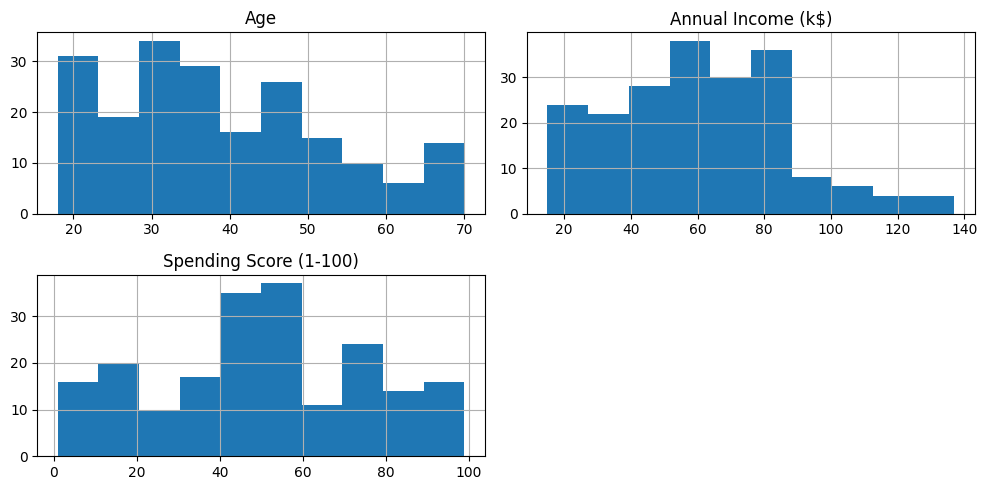

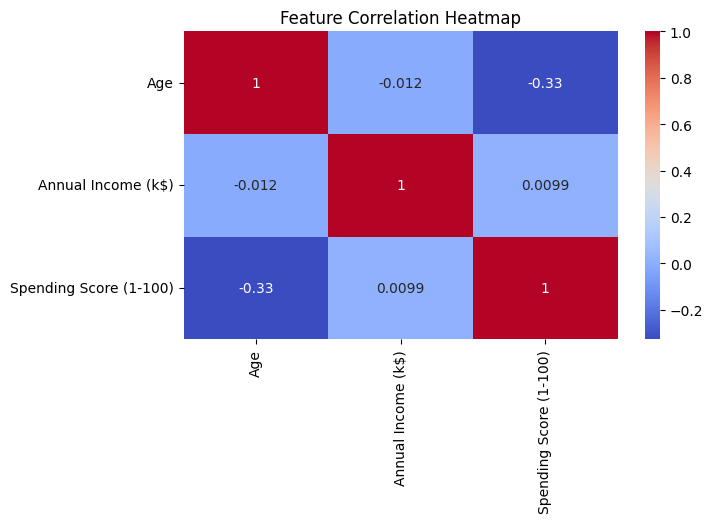

In [3]:
# Visualize feature distributions
df[['Age', 'Annual Income (k$)',
    'Spending Score (1-100)']].hist(figsize=(10, 5))

plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(7, 4))
sns.heatmap(
    df[['Age', 'Annual Income (k$)',
        'Spending Score (1-100)']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [4]:
features = ['Age', 'Annual Income (k$)',
            'Spending Score (1-100)']

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First 5 rows of scaled data:")
print(X_scaled[:5])

First 5 rows of scaled data:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


    K  Inertia  Silhouette Score  Davies-Bouldin Index
0   2  389.386             0.335                 1.261
1   3  295.212             0.358                 1.050
2   4  205.225             0.404                 0.931
3   5  168.248             0.417                 0.875
4   6  133.868             0.428                 0.825
5   7  117.012             0.417                 0.793
6   8  103.873             0.408                 0.892
7   9   93.093             0.418                 0.820
8  10   82.385             0.407                 0.868


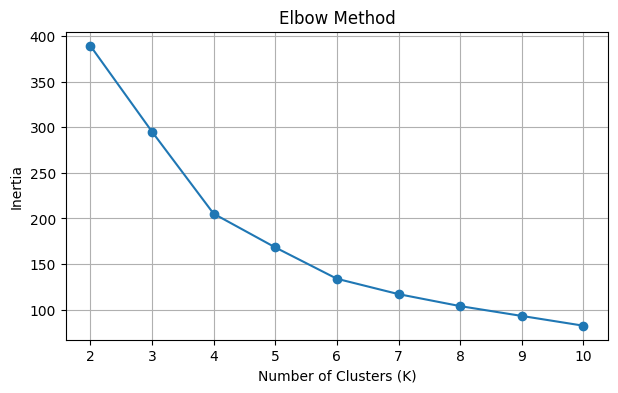

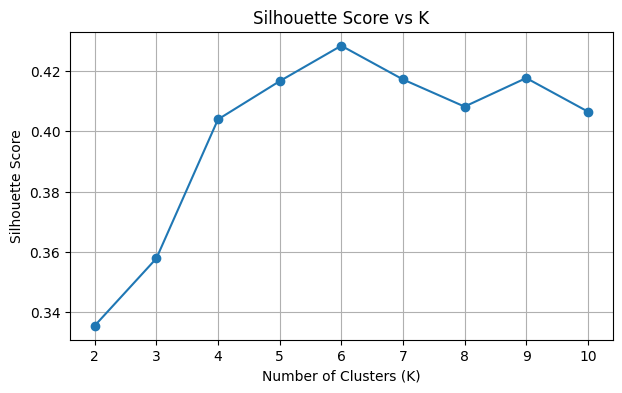

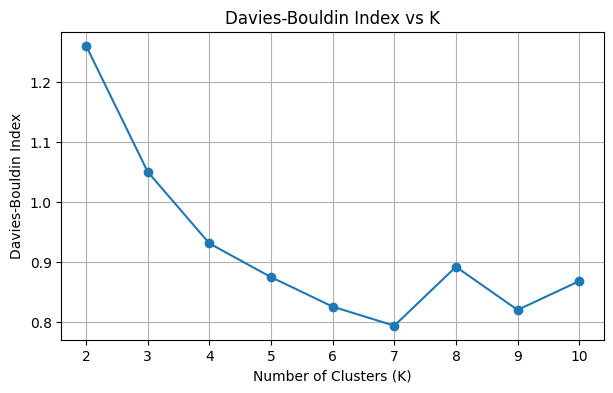

Best K by Silhouette Score: 6
Best K by Davies-Bouldin Index: 7


In [5]:
inertia = []
silhouette = []
db_scores = []

K = range(2, 11)
for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

# Display evaluation results
results = pd.DataFrame({
    'K': list(K),
    'Inertia': inertia,
    'Silhouette Score': silhouette,
    'Davies-Bouldin Index': db_scores
})
print(results.round(3))

# Elbow Method
plt.figure(figsize=(7, 4))
plt.plot(K, inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(K)
plt.grid()
plt.show()

# Silhouette Score
plt.figure(figsize=(7, 4))
plt.plot(K, silhouette, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.xticks(K)
plt.grid()
plt.show()

# Davies-Bouldin Index
plt.figure(figsize=(7, 4))
plt.plot(K, db_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index vs K")
plt.xticks(K)
plt.grid()
plt.show()

print("Best K by Silhouette Score:",
      list(K)[np.argmax(silhouette)])

print("Best K by Davies-Bouldin Index:",
      list(K)[np.argmin(db_scores)])

In [6]:
optimal_k = 6

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Customer Cluster Assignments:")
print(df[['Age', 'Annual Income (k$)',
          'Spending Score (1-100)', 'Cluster']].head(10))


print("\nFinal Silhouette Score:",
      silhouette_score(X_scaled, df['Cluster']))

print("Final Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, df['Cluster']))

Customer Cluster Assignments:
   Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0   19                  15                      39        4
1   21                  15                      81        4
2   20                  16                       6        5
3   23                  16                      77        4
4   31                  17                      40        5
5   22                  17                      76        4
6   35                  18                       6        5
7   23                  18                      94        4
8   64                  19                       3        5
9   30                  19                      72        4

Final Silhouette Score: 0.4284167762892593
Final Davies-Bouldin Index: 0.8253539040983219


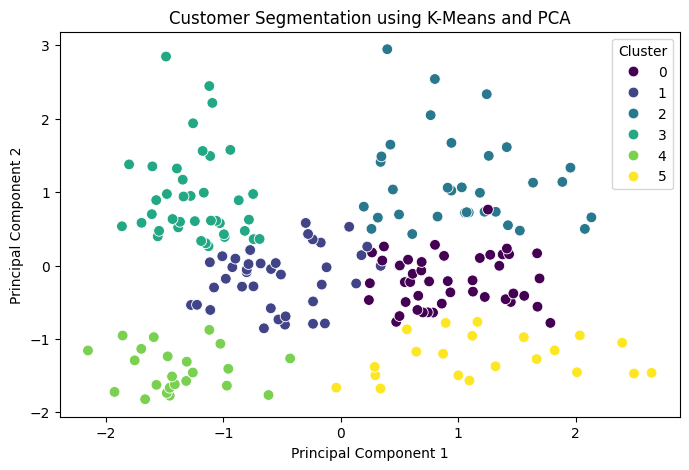

In [7]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    s=60
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

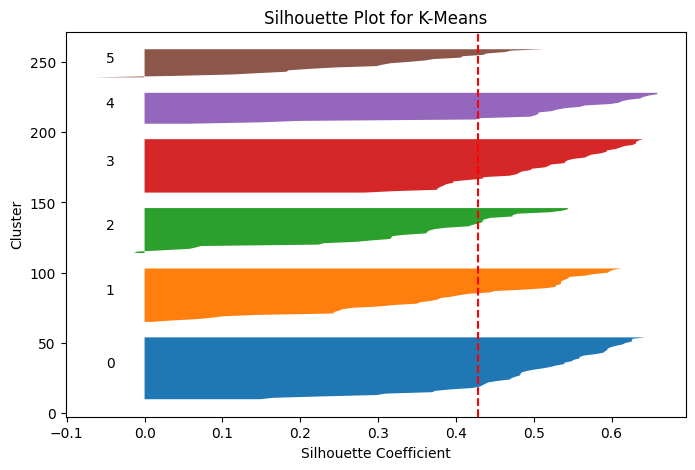

In [8]:
sample_values = silhouette_samples(
    X_scaled,
    df['Cluster']
)

y_lower = 10

plt.figure(figsize=(8, 5))

for i in range(optimal_k):

    values = sample_values[df['Cluster'] == i]
    values.sort()

    size = len(values)
    y_upper = y_lower + size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        values
    )

    plt.text(-0.05, y_lower + size / 2, str(i))

    y_lower = y_upper + 10


plt.axvline(
    silhouette_score(X_scaled, df['Cluster']),
    color='red',
    linestyle='--'
)

plt.title("Silhouette Plot for K-Means")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster")
plt.show()

In [9]:
profile = df.groupby('Cluster').agg(
    Customer_Count=('Cluster', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Annual Income (k$)', 'mean'),
    Mean_Spending=('Spending Score (1-100)', 'mean')
).round(2)

print("Customer Segment Profiles:")
print(profile)

Customer Segment Profiles:
         Customer_Count  Mean_Age  Mean_Income  Mean_Spending
Cluster                                                      
0                    45     56.33        54.27          49.07
1                    39     26.79        57.10          48.13
2                    33     41.94        88.94          16.97
3                    39     32.69        86.54          82.13
4                    23     25.00        25.26          77.61
5                    21     45.52        26.29          19.38


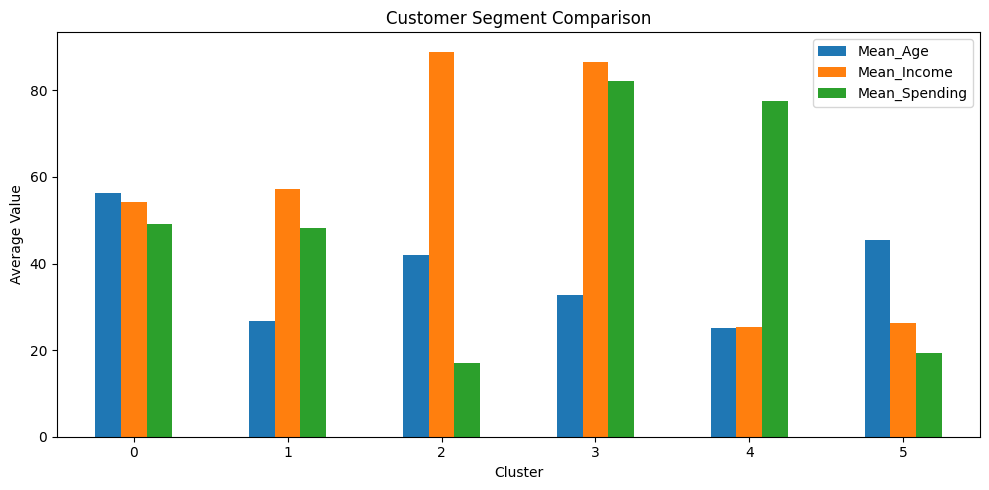

In [10]:
profile[['Mean_Age', 'Mean_Income',
         'Mean_Spending']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Customer Segment Comparison")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

Silhouette Score without scaling: 0.4523443947724053
Silhouette Score with scaling: 0.4284167762892593
Adjusted Rand Index: 0.9554608531223658


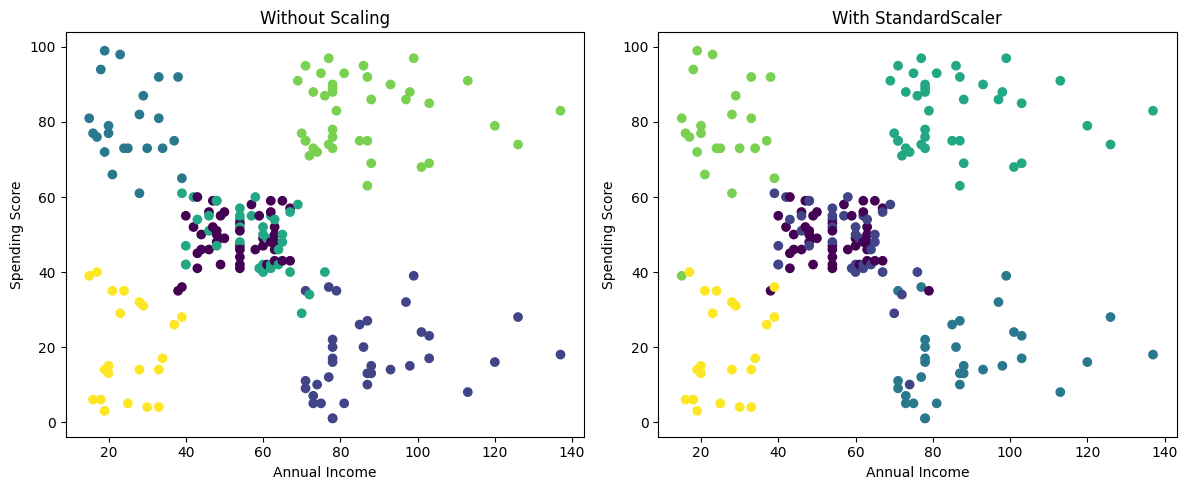

In [11]:
# K-Means without scaling
kmeans_original = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

labels_original = kmeans_original.fit_predict(X)


# K-Means with scaling
kmeans_scaled = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

labels_scaled = kmeans_scaled.fit_predict(X_scaled)


# Compare silhouette scores
print("Silhouette Score without scaling:",
      silhouette_score(X, labels_original))

print("Silhouette Score with scaling:",
      silhouette_score(X_scaled, labels_scaled))


# Compare cluster assignments
print("Adjusted Rand Index:",
      adjusted_rand_score(labels_original, labels_scaled))


# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=labels_original,
    cmap='viridis'
)

axes[0].set_title("Without Scaling")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")


axes[1].scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=labels_scaled,
    cmap='viridis'
)
axes[1].set_title("With StandardScaler")
axes[1].set_xlabel("Annual Income")
axes[1].set_ylabel("Spending Score")

plt.tight_layout()
plt.show()